# Similar cases, prototypes, and criticisms

A court uses a model that predicts whether a defendant is rearrested within two years. This
notebook explains with **examples** in place of feature weights:

1. *Similar cases:* "people like this defendant, and what happened to them".
2. *Prototypes:* a few people that represent all the training data.
3. *Criticisms:* people that the prototypes do not represent. They help to find data problems.

In [1]:
import warnings

import kmedoids
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from recidivism_data import FEATURES, TARGET, load, onehot
from recidivism_data.shared import opaque_model, person
from recidivism_data.theme import BLUE, INK, INK2, MUTED, ORANGE, use_theme
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
use_theme()
pd.set_option("display.width", 200)

train = load().query("split == 'train'").reset_index(drop=True)
scaler = StandardScaler().fit(onehot(train[FEATURES]))


def scaled(X: pd.DataFrame) -> np.ndarray:
    """All features as numbers on the same scale, so that a distance has a meaning."""
    return scaler.transform(onehot(X[FEATURES]))


model = opaque_model()
one = person()
print(one.to_string(index=False))
print(f"\nopaque model: P(rearrest) = {model.predict_proba(one)[0, 1]:.2f}")

 age  sex  priors_count  juvenile_priors  age_at_first_arrest charge_degree charge_type  employed  in_treatment county
  24 male             5                0                   17        felony        drug         0             0  south

opaque model: P(rearrest) = 0.69


## 1. Similar cases (k nearest neighbors)

Find the training people with the smallest distance to the defendant and show what happened
to them. A judge can examine these cases, which is not possible with a list of weights.

In [2]:
neighbors = NearestNeighbors(n_neighbors=25).fit(scaled(train))
distance, index = neighbors.kneighbors(scaled(one))
similar = train.loc[index[0], [*FEATURES, TARGET]].assign(distance=distance[0].round(2))
print(f"rearrested among the 25 most similar people: {similar[TARGET].mean():.0%}")
similar.head(6)

rearrested among the 25 most similar people: 84%


,age,sex,priors_count,juvenile_priors,age_at_first_arrest,charge_degree,charge_type,employed,in_treatment,county,rearrested,distance
6875,25,male,5,0,19,felony,drug,0,0,south,0,0.21
380,24,male,4,0,12,felony,drug,0,0,south,1,0.61
1115,22,male,6,0,12,felony,drug,0,0,south,1,0.64
5172,21,male,4,0,12,felony,drug,0,0,south,0,0.68
658,26,male,3,0,17,felony,drug,0,0,south,1,0.85
4496,23,male,2,0,17,felony,drug,0,0,south,1,1.25


A prediction from the neighbors (k-nearest-neighbor classification) is inherently
interpretable, **if the distance is intuitive**. This distance is not: each feature has the
same weight, so the county counts as much as the number of priors. All six neighbors are from
the county `south`. Without the two features that are not causes of a rearrest, other people
are the "most similar":

In [3]:
relevant = [
    c for c in onehot(train[FEATURES]).columns if not c.startswith(("county", "age_at_first"))
]
position = [list(onehot(train[FEATURES]).columns).index(c) for c in relevant]
neighbors2 = NearestNeighbors(n_neighbors=25).fit(scaled(train)[:, position])
_, index2 = neighbors2.kneighbors(scaled(one)[:, position])
print(f"rearrested among the 25 most similar people: {train.loc[index2[0], TARGET].mean():.0%}")
print(f"people in both lists of 25: {len(set(index[0]) & set(index2[0]))}")
train.loc[index2[0], [*FEATURES, TARGET]].head(6)

rearrested among the 25 most similar people: 76%
people in both lists of 25: 6


,age,sex,priors_count,juvenile_priors,age_at_first_arrest,charge_degree,charge_type,employed,in_treatment,county,rearrested
6875,25,male,5,0,19,felony,drug,0,0,south,0
380,24,male,4,0,12,felony,drug,0,0,south,1
2683,23,male,6,0,12,felony,drug,0,0,west,1
1115,22,male,6,0,12,felony,drug,0,0,south,1
99,22,male,4,0,12,felony,drug,0,0,north,1
5172,21,male,4,0,12,felony,drug,0,0,south,0


## 2. Prototypes

A prototype is a real person that represents many others. **k-medoids** is like k-means, but
each cluster center is an actual data point, so you can show it. (The center of a k-means
cluster is an average, e.g. a person who is 61% male.)

In [4]:
sample = train.sample(3000, random_state=0).reset_index(drop=True)
distances = pairwise_distances(scaled(sample))
clusters = kmedoids.fasterpam(distances, 6, random_state=0)
prototypes = sample.loc[clusters.medoids, FEATURES].reset_index(drop=True)
prototypes["people"] = np.bincount(clusters.labels, minlength=6)
prototypes["rearrested"] = sample.groupby(clusters.labels)[TARGET].mean().round(2).to_numpy()
prototypes.sort_values("people", ascending=False)

,age,sex,priors_count,juvenile_priors,age_at_first_arrest,charge_degree,charge_type,employed,in_treatment,county,people,rearrested
5,30,male,1,0,24,misdemeanor,property,0,0,north,685,0.43
4,30,male,1,0,27,misdemeanor,drug,1,0,north,665,0.38
1,28,male,1,0,22,felony,violent,0,0,north,463,0.39
0,38,male,1,0,29,felony,other,1,0,west,455,0.33
2,33,male,5,1,17,felony,other,0,0,south,423,0.61
3,29,male,1,0,25,misdemeanor,traffic,1,0,north,309,0.32


**In two dimensions.** With only `age` and `priors_count` as features, the distance of the
method is the distance in the plot. The number above a prototype is the share of the people
for whom it is the nearest prototype. The criticisms are the people farthest from each
prototype (a candidate next to a criticism that is already chosen is skipped).

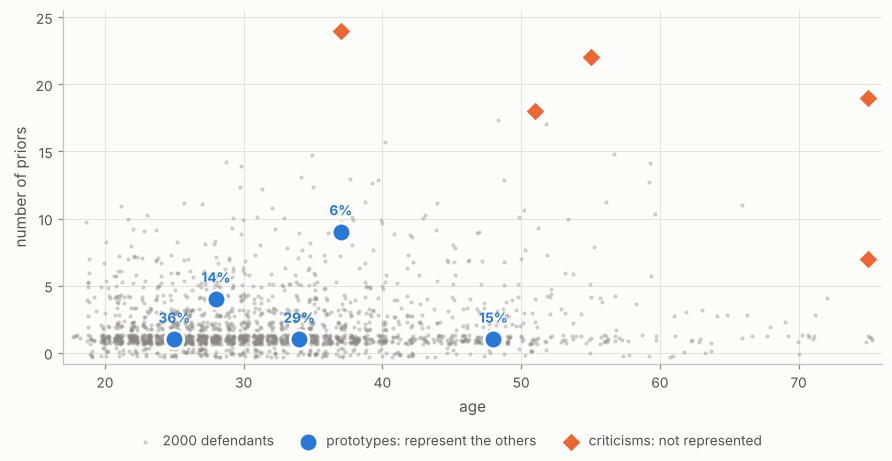

,age,priors_count,share
0,25,1,36%
1,48,1,15%
2,37,9,6%
3,28,4,14%
4,34,1,29%


In [5]:
two = ["age", "priors_count"]
few = train.sample(2000, random_state=0).reset_index(drop=True)
Z = ((few[two] - few[two].mean()) / few[two].std()).to_numpy()
D2 = pairwise_distances(Z)
clusters2 = kmedoids.fasterpam(D2, 5, random_state=0)
medoids, nearest = list(clusters2.medoids), clusters2.labels
far = D2[:, medoids].min(axis=1)
critics: list[int] = []
for i in np.argsort(-far):
    if all(D2[i, c] > 1.5 for c in critics):
        critics.append(int(i))
    if len(critics) == 5:
        break

jitter = np.random.default_rng(0).uniform(
    -0.35, 0.35, (len(few), 2)
)  # the values are whole numbers
fig, ax = plt.subplots(figsize=(8, 4.1))
ax.scatter(
    few["age"] + jitter[:, 0],
    few["priors_count"] + jitter[:, 1],
    s=7,
    color=MUTED,
    alpha=0.4,
    linewidth=0,
    label="2000 defendants",
)
ax.scatter(
    few.loc[medoids, "age"],
    few.loc[medoids, "priors_count"],
    s=150,
    color=BLUE,
    edgecolor="white",
    linewidth=1.8,
    zorder=4,
    label="prototypes: represent the others",
)
ax.scatter(
    few.loc[critics, "age"],
    few.loc[critics, "priors_count"],
    s=95,
    marker="D",
    color=ORANGE,
    edgecolor="white",
    linewidth=1.6,
    zorder=4,
    label="criticisms: not represented",
)
for k, m in enumerate(medoids):
    share = f"{np.mean(nearest == k):.0%}"
    ax.annotate(
        share,
        (few.loc[m, "age"], few.loc[m, "priors_count"]),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        color=BLUE,
        fontsize=9,
        fontweight="bold",
    )
ax.set(
    xlabel="age",
    ylabel="number of priors",
    xlim=(17, 76),
    ylim=(-0.8, few["priors_count"].max() + 1.5),
)
fig.legend(
    loc="outside lower center",
    ncols=3,
    labelcolor=INK2,
    fontsize=9,
    columnspacing=1.5,
    handletextpad=0.3,
)
plt.show()
few.loc[medoids, two].assign(share=[f"{np.mean(nearest == k):.0%}" for k in range(5)]).reset_index(
    drop=True
)

Six people give a first idea of who is in the data. Five of them are about 30 years old with
one prior, and differ in the charge and the employment. Only one represents the people with
more priors, although these people are the most important ones for the model: prototypes use
**all features**, not the features that are important for the prediction.

## 3. Criticisms

A criticism is a person that the prototypes do not represent. The simplest definition: the
people with the largest distance to their nearest prototype.

Here we use the **dirty** copy of the training data. It has data-entry errors in 60 rows
(`priors_count + 90`, `age + 100`, flipped labels), and a log of them.

In [6]:
dirty = load("defendants_dirty").query("split == 'train'").reset_index(drop=True)
log = load("error_log")
wrong_value = set(log.loc[log["column"] != TARGET, "id"])
wrong_label_only = set(log["id"]) - wrong_value

dirty_sample = dirty.sample(3000, random_state=0).reset_index(drop=True)
dirty_distances = pairwise_distances(scaled(dirty_sample))
dirty_clusters = kmedoids.fasterpam(dirty_distances, 6, random_state=0)
to_prototype = dirty_distances[:, dirty_clusters.medoids].min(axis=1)
criticisms = dirty_sample.loc[np.argsort(-to_prototype)[:20]].assign(
    distance=np.sort(to_prototype)[::-1][:20].round(1)
)
criticisms["injected error"] = criticisms["id"].isin(wrong_value)

in_sample = dirty_sample["id"].isin(wrong_value).sum()
print(f"rows with a wrong value in the sample of 3000: {in_sample}")
print(f"of the 20 criticisms, {criticisms['injected error'].sum()} are such rows")
print(
    f"rows with only a flipped label in the sample: {dirty_sample['id'].isin(wrong_label_only).sum()}, among the criticisms: {criticisms['id'].isin(wrong_label_only).sum()}"
)
criticisms[
    ["age", "priors_count", "age_at_first_arrest", "charge_type", "distance", "injected error"]
].head(10)

rows with a wrong value in the sample of 3000: 14
of the 20 criticisms, 14 are such rows
rows with only a flipped label in the sample: 7, among the criticisms: 0


,age,priors_count,age_at_first_arrest,charge_type,distance,injected error
1736,46,92,42,violent,36.4,True
801,53,91,49,drug,36.2,True
2621,23,92,12,other,36.2,True
2155,42,91,41,traffic,36.1,True
228,23,91,21,traffic,35.9,True
177,35,91,34,property,35.9,True
1300,23,91,17,violent,35.8,True
1189,45,90,45,traffic,35.5,True
461,134,1,29,drug,10.3,True
353,55,22,12,property,10.2,False


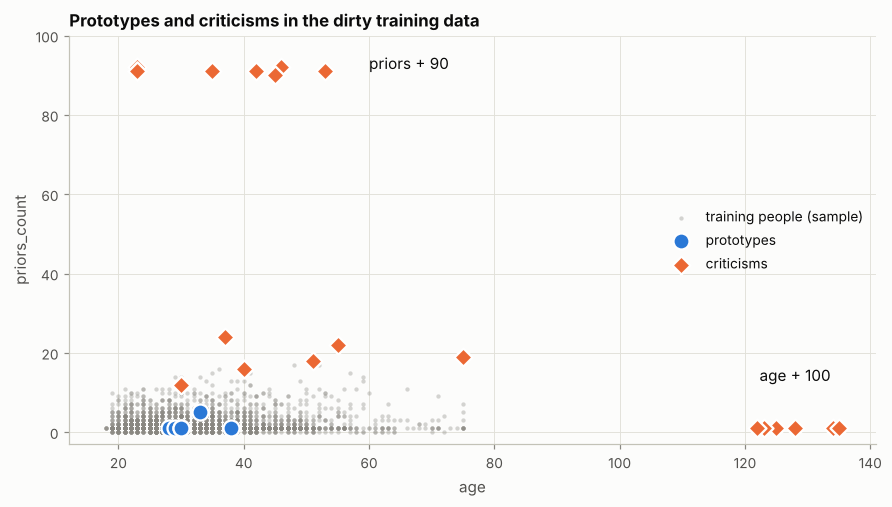

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(
    dirty_sample["age"],
    dirty_sample["priors_count"],
    s=8,
    color=MUTED,
    alpha=0.35,
    linewidth=0,
    label="training people (sample)",
)
shown = dirty_sample.loc[dirty_clusters.medoids]
ax.scatter(
    shown["age"],
    shown["priors_count"],
    s=110,
    color=BLUE,
    edgecolor="white",
    linewidth=1.5,
    label="prototypes",
    zorder=3,
)
ax.scatter(
    criticisms["age"],
    criticisms["priors_count"],
    s=70,
    marker="D",
    color=ORANGE,
    edgecolor="white",
    linewidth=1.5,
    label="criticisms",
    zorder=3,
)
ax.annotate("priors + 90", (60, 93), color=INK, ha="left", va="center")
ax.annotate("age + 100", (128, 12), color=INK, ha="center", va="bottom")
ax.set(
    xlabel="age",
    ylabel="priors_count",
    title="Prototypes and criticisms in the dirty training data",
    ylim=(-3, 100),
)
ax.legend(loc="center right")
plt.show()

All rows with an impossible value are among the criticisms; you would see them at once.
But a **flipped label** does not make a person unusual: no criticism is such a row. Prototypes
and criticisms look only at the features. Project 07 (influential instances) finds some of
these rows.

## 4. MMD-critic

The far-from-a-prototype rule finds single outliers. [MMD-critic](https://papers.nips.cc/paper/2016/hash/5680522b8e2bb01943234bce7bf84534-Abstract.html)
has a different goal. It selects prototypes so that their distribution is as near as possible
to the distribution of the data (a small *maximum mean discrepancy*), and criticisms where the
two distributions differ most: **groups** of people that the prototypes describe badly.

In [8]:
def mmd_prototypes(kernel: np.ndarray, count: int) -> list[int]:
    """Greedy: add the point that decreases the discrepancy between prototypes and data most."""
    data_density = kernel.mean(axis=0)
    selected: list[int] = []
    for _ in range(count):
        size = len(selected) + 1
        fit = 2 * (data_density[selected].sum() + data_density) / size
        among = (
            kernel[np.ix_(selected, selected)].sum()
            + 2 * kernel[:, selected].sum(axis=1)
            + kernel.diagonal()
        )
        gain = fit - among / size**2
        gain[selected] = -np.inf
        selected.append(int(np.argmax(gain)))
    return selected


def mmd_criticisms(kernel: np.ndarray, prototypes: list[int], count: int) -> list[int]:
    """The points where the data is dense but the prototypes are far (largest witness value)."""
    witness = kernel.mean(axis=0) - kernel[:, prototypes].mean(axis=1)
    selected: list[int] = []
    for _ in range(count):
        penalty = kernel[:, selected].sum(axis=1) if selected else 0  # not the same group again
        score = witness - 0.1 * penalty
        score[prototypes + selected] = -np.inf
        selected.append(int(np.argmax(score)))
    return selected


kernel = rbf_kernel(scaled(sample), gamma=1 / scaled(sample).shape[1])
mmd_p = mmd_prototypes(kernel, 6)
mmd_c = mmd_criticisms(kernel, mmd_p, 5)
print("prototypes:")
print(sample.loc[mmd_p, FEATURES].to_string(index=False))
print("\ncriticisms:")
print(sample.loc[mmd_c, FEATURES].to_string(index=False))

prototypes:
 age    sex  priors_count  juvenile_priors  age_at_first_arrest charge_degree charge_type  employed  in_treatment county
  30   male             2                0                   26   misdemeanor       other         1             0  north
  34   male             1                1                   17        felony    property         0             0   east
  31   male             1                0                   30        felony        drug         0             1   west
  30 female             2                0                   25        felony     violent         1             0  south
  35   male             5                1                   17   misdemeanor        drug         0             0  south
  36   male             1                0                   33   misdemeanor    property         1             0   west

criticisms:
 age    sex  priors_count  juvenile_priors  age_at_first_arrest charge_degree charge_type  employed  in_treatment county
  25 fe

Compare the criticisms with the prototypes: they show kinds of people to which the six
prototypes give too little weight, e.g. an old man, and people with many priors and juvenile
priors. The number of prototypes and criticisms is your decision, and the result depends on
it.